# Semana 3: Validación Númerica de la Propiedad de Martingala (Monte Carlo)

Importamos librerias que vamos a utilizar

In [4]:
import numpy as np
import matplotlib.pyplot as plt

Definimos la escala del experimento

In [6]:
# Parámetros temporales
T = 1
N = 500
dt = T / N

# Escala de Monte Carlo (Número de trayectorias independientes)
M = 10000

El bucle de validación

In [7]:
# Creamos el eje del tiempo (0, T)
tiempo = np.linspace(0, T, N+1)

# Preparamos la matriz contenedora de ceros
trayectorias = np.zeros((N+1, M)) # Al ya estar llena de ceros, la fila 0 cumple W_0 = 0

# El bucle de validación Monte Carlo
for j in range(M):
    incrementos = np.random.normal(0, np.sqrt(dt), N) # Los N "empujones" aleatorios

    trayectorias[1:, j] = np.cumsum(incrementos) # Guardamos la suma acumulada a partir de la fila 1 en la columna "j"

# Calculamos la media empírica a travez de las 10,000 trayectorias
media_empirica = np.mean(trayectorias, axis=1) 

print("Últimos 5 valores de la media acumulada: ", media_empirica[-5:])

Últimos 5 valores de la media acumulada:  [ 7.40000642e-04 -3.12188044e-04  1.67170329e-04 -5.61388820e-05
  7.77519515e-04]


Ahora, vamos a graficar la Propiedad de Martingala

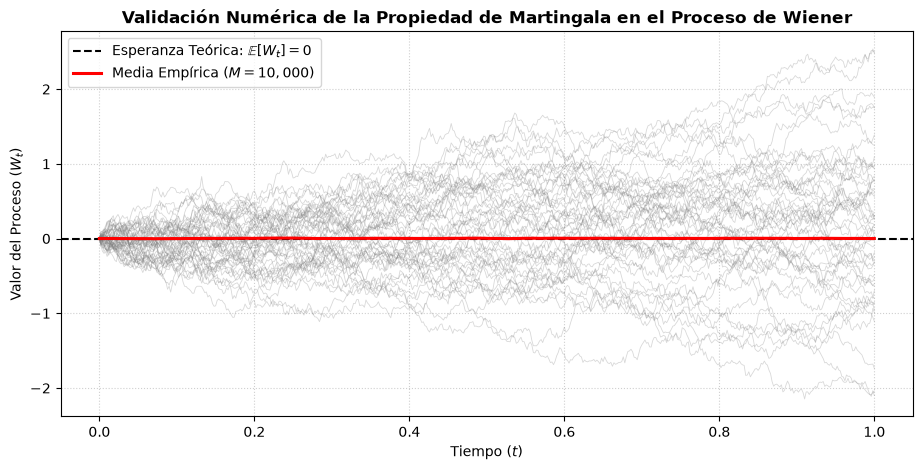

In [10]:
plt.figure(figsize=(11, 5))

# Graficamos solo las primeras 50 trayectorias de fondo para no saturar la vista 
plt.plot(tiempo, trayectorias[: , :50], color='gray', linewidth=0.6, alpha=0.3)

# Graficamos la línea teórica exacta (E[W_t]=0)
plt.axhline(0, color='black', linewidth=1.5, linestyle='--', label=r'Esperanza Teórica: $\mathbb{E}[W_t] = 0 $')

# Graficamos la media empírica de las 10,000 simulaciones
plt.plot(tiempo, media_empirica, color='red', linewidth=2.2, label='Media Empírica ($M=10,000$)')

# Detalles de la gráfica
plt.title("Validación Numérica de la Propiedad de Martingala en el Proceso de Wiener", fontsize=12, fontweight='bold')
plt.xlabel("Tiempo ($t$)", fontsize=10)
plt.ylabel("Valor del Proceso ($W_t$)", fontsize=10)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)

Esta gráfica demuestra visualmente que el Proceso de Wiener no tiene deriva ni tendencia sistemática hacia arriba o hacia abajo. Es un juego justo, que es la esencia de una martingala.
